# ELET 6303 - Applied Neural Networks Project 2

## Option 3 - Reinforcement Learning for Smart Energy Management

#### Subhan Mehmood

### Required Installs

In [52]:
# pip install ucimlrepo
# pip install numpy
# pip install matplotlib
# pip install pandas

### Libraries

In [53]:
# All libraries used 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

### Import Dataset

In [54]:
# Load the Individual Household Electric Power Consumption dataset from UCI Machine Learning Repository
# Backup plan: If the UCI fetch fails, try to read the dataset from a local file named "household_power_consumption.txt"


dataset = None

try:
    dataset = fetch_ucirepo(id=235)
    household_power_consumption = dataset.data.original.copy()
    print(household_power_consumption.head())
except Exception as error:
    print(f"UCI Fetch Failed - Error: {error}")

    try:
        dataset = fetch_ucirepo(name="household_power_consumption")
        household_power_consumption = dataset.data.original.copy()
        print(household_power_consumption.head())
    except Exception as error:
        print(f"UCI Fetch Failed - Error: {error}")
    
        try:
            household_power_consumption = pd.read_csv("household_power_consumption.txt", sep=';', low_memory=False, na_values='?')
            print(household_power_consumption.head())
        except Exception as error:
            print(f"Local File Read Failed - Error: {error}")

         Date      Time Global_active_power Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00               4.216                 0.418  234.840   
1  16/12/2006  17:25:00               5.360                 0.436  233.630   
2  16/12/2006  17:26:00               5.374                 0.498  233.290   
3  16/12/2006  17:27:00               5.388                 0.502  233.740   
4  16/12/2006  17:28:00               3.666                 0.528  235.680   

  Global_intensity Sub_metering_1 Sub_metering_2  Sub_metering_3  
0           18.400          0.000          1.000            17.0  
1           23.000          0.000          1.000            16.0  
2           23.000          0.000          2.000            17.0  
3           23.000          0.000          1.000            17.0  
4           15.800          0.000          1.000            17.0  


### Data Exploration

In [55]:
# Derive information about the dataset

if dataset is None:
    print("UCI Fetch Failed")
else:
    print("Metadata:")
    print(dataset.metadata)

print("\nDescribe:")
print(household_power_consumption.describe(include="all"))

print("\nInfo:")
print(household_power_consumption.info())

print("\nShape:")
print(household_power_consumption.shape)

print("\nColumns:")
print(household_power_consumption.columns)

print("\nData Types:")
print(household_power_consumption.dtypes)

Metadata:
{'uci_id': 235, 'name': 'Individual Household Electric Power Consumption', 'repository_url': 'https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption', 'data_url': 'https://archive.ics.uci.edu/static/public/235/data.csv', 'abstract': 'Measurements of electric power consumption in one household with a one-minute sampling rate over a period of almost 4 years. Different electrical quantities and some sub-metering values are available.', 'area': 'Physics and Chemistry', 'tasks': ['Regression', 'Clustering'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 2075259, 'num_features': 9, 'feature_types': ['Real'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2006, 'last_updated': 'Fri Mar 08 2024', 'dataset_doi': '10.24432/C58K54', 'creators': ['Georges Hebrail', 'Alice Berard'], 'intro_paper': None, 'additional_info': {'summary': 'T

In [56]:
# Derive more information about the dataset

features = ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

print("\nDuplicate rows:")
print(household_power_consumption.duplicated().sum())


Duplicate rows:
0


In [57]:
# Additional check for duplicates and display them if any exist

duplicates = household_power_consumption[household_power_consumption.duplicated(keep=False)]

duplicates = duplicates.sort_values(by=list(household_power_consumption.columns))

display(duplicates)

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3


### Data Preprocessing

In [58]:
# Convert features to numeric

for feature in features:
    household_power_consumption[feature] = pd.to_numeric(household_power_consumption[feature], errors='coerce')

In [59]:
# Check for nulls

household_power_consumption.isnull().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [60]:
# Create Datetime feature from Date and Time

household_power_consumption["Datetime"] = pd.to_datetime(household_power_consumption["Date"].astype(str) + ' ' + household_power_consumption["Time"].astype(str), format="%d/%m/%Y %H:%M:%S", errors='coerce')
household_power_consumption.set_index("Datetime", inplace=True)
household_power_consumption.drop(columns=["Date", "Time"], inplace=True)

In [61]:
# Check date range

household_power_consumption.index.min(), household_power_consumption.index.max()

(Timestamp('2006-12-16 17:24:00'), Timestamp('2010-11-26 21:02:00'))

In [62]:
# Create variable, hourly, for average active power per hour for each datetime

hourly = household_power_consumption['Global_active_power'].resample('h').mean()

In [63]:
# Get first 10 entries for hourly variable

hourly.head(10)

Datetime
2006-12-16 17:00:00    4.222889
2006-12-16 18:00:00    3.632200
2006-12-16 19:00:00    3.400233
2006-12-16 20:00:00    3.268567
2006-12-16 21:00:00    3.056467
2006-12-16 22:00:00    2.200133
2006-12-16 23:00:00    2.061600
2006-12-17 00:00:00    1.882467
2006-12-17 01:00:00    3.349400
2006-12-17 02:00:00    1.587267
Freq: h, Name: Global_active_power, dtype: float64

In [64]:
# Get last 10 entries for hourly variable

hourly.tail(10)

Datetime
2010-11-26 12:00:00    1.490200
2010-11-26 13:00:00    1.612933
2010-11-26 14:00:00    1.407767
2010-11-26 15:00:00    0.876433
2010-11-26 16:00:00    1.067933
2010-11-26 17:00:00    1.725900
2010-11-26 18:00:00    1.573467
2010-11-26 19:00:00    1.659333
2010-11-26 20:00:00    1.163700
2010-11-26 21:00:00    0.934667
Freq: h, Name: Global_active_power, dtype: float64

In [65]:
# Create variable, minutes_per_hour, for the total number of active power minutes per hour for each datetime

minutes_per_hour = household_power_consumption['Global_active_power'].resample('h').count()
minutes_per_hour

Datetime
2006-12-16 17:00:00    36
2006-12-16 18:00:00    60
2006-12-16 19:00:00    60
2006-12-16 20:00:00    60
2006-12-16 21:00:00    60
                       ..
2010-11-26 17:00:00    60
2010-11-26 18:00:00    60
2010-11-26 19:00:00    60
2010-11-26 20:00:00    60
2010-11-26 21:00:00     3
Freq: h, Name: Global_active_power, Length: 34589, dtype: int64

In [66]:
# Mark hours with fewer than 45 recorded minutes as missing (NaN)

MIN_MINUTES = 45

low_coverage = minutes_per_hour < MIN_MINUTES

print(f"NaN Hours Before Filtering: {hourly.isnull().sum()}")
print(f"Hours Flagged as Low Coverage: {low_coverage.sum()}")

hourly = hourly.mask(low_coverage)

print(f"NaN Hours After Filtering: {hourly.isnull().sum()}")

NaN Hours Before Filtering: 421
Hours Flagged as Low Coverage: 438
NaN Hours After Filtering: 438


In [67]:
# Create variable, hours_per_day, to count total hours for each datetime and list datetimes with less than 24 hours (incomplete days)

hours_per_day = hourly.groupby(hourly.index.date).count()

hours_per_day[hours_per_day < 24]

2006-12-16     6
2007-04-28     0
2007-04-29     0
2007-04-30     9
2007-06-09    23
2007-07-15    22
2007-08-01    23
2008-10-25    23
2008-12-10    23
2009-02-01    23
2009-02-17    23
2009-06-13     0
2009-06-14     0
2009-06-15    16
2009-08-13     9
2010-01-12    15
2010-01-13     0
2010-01-14     5
2010-03-20     4
2010-03-21    10
2010-08-17    21
2010-08-18     0
2010-08-19     0
2010-08-20     0
2010-08-21     0
2010-08-22     2
2010-09-25     4
2010-09-26     0
2010-09-27     0
2010-09-28     5
2010-11-26    21
Name: Global_active_power, dtype: int64

In [68]:
# Filter out incomplete days/hours and retain only full days in the variable, hourly_clean

complete_days = hours_per_day[hours_per_day == 24].index

hourly_mask = np.isin(hourly.index.date, complete_days)

hourly_clean = hourly[hourly_mask]

print(f"Length of hourly_clean: {len(hourly_clean)}")
print(f"Length of hourly: {len(hourly)}")

print(f"Sum of hourly_clean: {hourly_clean.sum()}")

Length of hourly_clean: 33864
Length of hourly: 34589
Sum of hourly_clean: 36979.62996203129


In [69]:
# Check data cleanup

print(f"Total Days Before: {len(hours_per_day)}")
print(f"Complete Days Kept: {len(complete_days)}")
print(f"Days Removed: {len(hours_per_day) - len(complete_days)}")
print(f"Dates Removed: {', '.join([str(date) for date in hours_per_day[hours_per_day < 24].index])}")

Total Days Before: 1442
Complete Days Kept: 1411
Days Removed: 31
Dates Removed: 2006-12-16, 2007-04-28, 2007-04-29, 2007-04-30, 2007-06-09, 2007-07-15, 2007-08-01, 2008-10-25, 2008-12-10, 2009-02-01, 2009-02-17, 2009-06-13, 2009-06-14, 2009-06-15, 2009-08-13, 2010-01-12, 2010-01-13, 2010-01-14, 2010-03-20, 2010-03-21, 2010-08-17, 2010-08-18, 2010-08-19, 2010-08-20, 2010-08-21, 2010-08-22, 2010-09-25, 2010-09-26, 2010-09-27, 2010-09-28, 2010-11-26


In [70]:
# Recheck null values after cleaning

print(f"Null Values in hourly_clean: {hourly_clean.isnull().sum()} \n")

clean_hours_per_day = hourly_clean.groupby(hourly_clean.index.date).count()

print(f"Days in Clean Data: {len(clean_hours_per_day)}")
print(f"Min Hours in a Day: {clean_hours_per_day.min()}")
print(f"Max Hours in a Day: {clean_hours_per_day.max()}")

Null Values in hourly_clean: 0 

Days in Clean Data: 1411
Min Hours in a Day: 24
Max Hours in a Day: 24


### Data Visualization

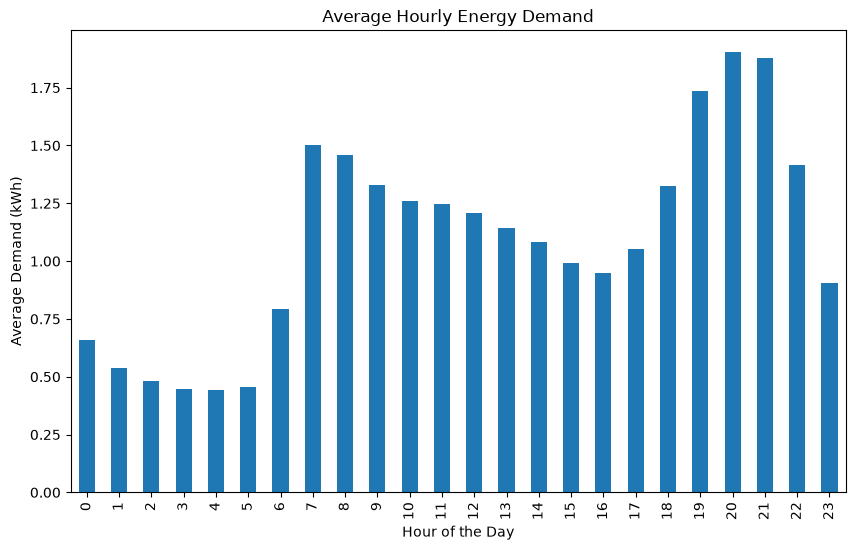

In [71]:
# Plot average hourly energy demand for all 24 hours

energy_plot = hourly_clean.groupby(hourly_clean.index.hour).mean().plot(
                                                            kind='bar',
                                                            xlabel='Hour of the Day',
                                                            ylabel='Average Demand (kWh)',
                                                            title='Average Hourly Energy Demand', 
                                                            figsize=(10, 6))

In [72]:
# Specify weekday and weekends and store them

day_of_week = hourly_clean.index.dayofweek

weekday = hourly_clean[day_of_week < 5]

weekend = hourly_clean[day_of_week >= 5]

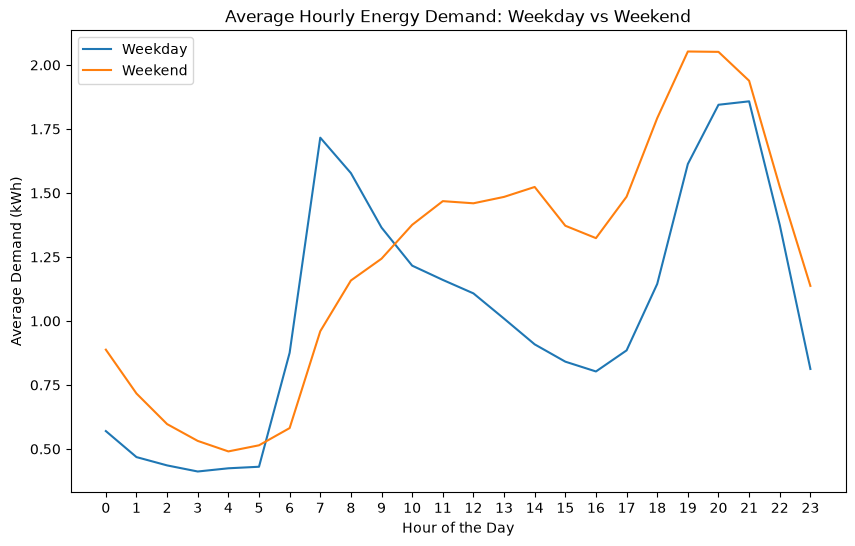

In [73]:
# Plot average hourly energy demand for weekdays and weekends

weekday_and_weekend = pd.concat([weekday.groupby(weekday.index.hour).mean(), weekend.groupby(weekend.index.hour).mean()], axis=1, keys=['Weekday', 'Weekend'])

weekday_weekend_plot = weekday_and_weekend.plot(
    xlabel='Hour of the Day',
    ylabel='Average Demand (kWh)',
    title='Average Hourly Energy Demand: Weekday vs Weekend',
    figsize=(10, 6),
    legend=True,
    xticks=np.arange(0, 24, 1)
    )

In [74]:
# Specify seasons (winter, summer, spring, fall) and store them

months = hourly_clean.index.month

winter = hourly_clean[months.isin([12, 1, 2])]

summer = hourly_clean[months.isin([6, 7, 8])]

spring = hourly_clean[months.isin([3, 4, 5])]

fall = hourly_clean[months.isin([9, 10, 11])]

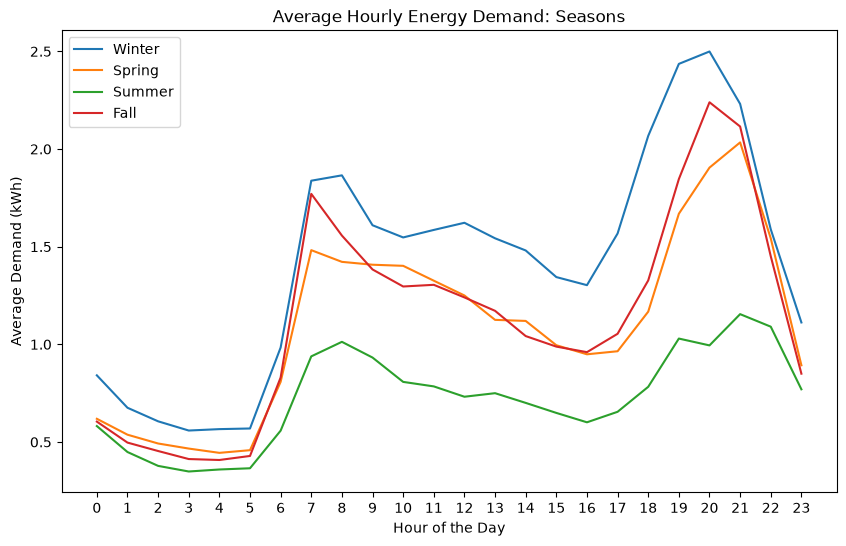

In [75]:
# Plot average hourly energy demand for all seasons (winter, summer, spring, fall)

seasons = pd.concat([winter.groupby(winter.index.hour).mean(), 
           spring.groupby(spring.index.hour).mean(), 
           summer.groupby(summer.index.hour).mean(), 
           fall.groupby(fall.index.hour).mean()], axis=1, keys=['Winter', 'Spring', 'Summer', 'Fall'])

seasons_plot = seasons.plot(
    xlabel='Hour of the Day',
    ylabel='Average Demand (kWh)',
    title='Average Hourly Energy Demand: Seasons',
    figsize=(10, 6),
    legend=True,
    xticks=np.arange(0, 24, 1)
)

### Model Preparation

In [76]:
# Split dataset (years) into train, validation, and test splits
# Train: 2006-2008 (learn the Q-table)
# Validation: 2009 (compare parameter settings)
# Test: 2010 (final evaluation only)

years = hourly_clean.index.year

train_series = hourly_clean[years < 2009]
val_series = hourly_clean[years == 2009]
test_series = hourly_clean[years >= 2010]

train_days = np.array(train_series)
val_days = np.array(val_series)
test_days = np.array(test_series)

train_days = train_days.reshape(-1, 24)
val_days = val_days.reshape(-1, 24)
test_days = test_days.reshape(-1, 24)

train_days.shape, val_days.shape, test_days.shape

((738, 24), (359, 24), (314, 24))

In [77]:
# Extract dates from train, validation, and test splits

train_dates = train_series.index.date[::24]

val_dates = val_series.index.date[::24]

test_dates = test_series.index.date[::24]

len(train_dates), len(val_dates), len(test_dates)

(738, 359, 314)

In [78]:
# Demand Bin Edges: 33rd and 67th percentile of training hourly demand (low/medium/high)

DEMAND_EDGES = np.percentile(train_days, [33, 67])
DEMAND_EDGES

array([0.36815067, 1.38824567])

In [79]:
# Simulated (chosen) Specifications 

# Tariff (USD per kWh), one price per hour 0–23
PRICE_OFF_PEAK = 0.15   # hours 22, 23, 0–5
PRICE_NORMAL = 0.22   # hours 6–15
PRICE_PEAK = 0.35   # hours 16–21
PRICES = np.array([PRICE_OFF_PEAK] * 6 + [PRICE_NORMAL] * 10 + [PRICE_PEAK] * 6 + [PRICE_OFF_PEAK] * 2) # price calculation --> 24 hourly prices: 6 off-peak, 10 normal, 6 peak, 2 off-peak

# Battery
CAPACITY = 10.0 # kWh, total battery size
SOC_MIN_FRAC = 0.1 # lowest allowed charge (10% of capacity)
SOC_MAX_FRAC = 0.9 # highest allowed charge (90% of capacity)
MAX_RATE = 2.0 # kWh per hour, max charge or discharge
ETA_C = 0.95 # charging efficiency
ETA_D = 0.95 # discharging efficiency

# Actions (kWh at the house/grid side; negative = discharge)
ACTIONS = [-2, -1, 0, 1, 2] 
DISCHARGE_2, DISCHARGE_1, IDLE, CHARGE_1, CHARGE_2 = 0, 1, 2, 3, 4 # names for the indexes into ACTIONS

# State Discretization
N_HOURS = 24
N_SOC_BINS = 10
N_DEMAND_BINS = 3 # edges come from DEMAND_EDGES (already computed)

# Reward
PENALTY = 0.5 # subtracted from reward for each invalid action

# Q-learning (baseline model)
ALPHA = 0.1 # learning rate
GAMMA = 1.0 # discount factor
EPSILON_START = 1.0 # fully random at the start
EPSILON_END = 0.05 # mostly greedy at the end
EPSILON_DECAY = 0.8 # fraction of episodes over which epsilon decays from 1.0 to 0.05
N_EPISODES = 50000 # around 68 passes over the 738 training days, around 330 updates per Q entry
SEED = 6333 # for reproducibility

print(f"Price per Hour: {PRICES}")

Price per Hour: [0.15 0.15 0.15 0.15 0.15 0.15 0.22 0.22 0.22 0.22 0.22 0.22 0.22 0.22
 0.22 0.22 0.35 0.35 0.35 0.35 0.35 0.35 0.15 0.15]


### Battery Environment and Policies

In [80]:
# AI-Assisted

# Battery class to create simulated battery

# Define class and battery parameters
class BatteryEnv:
    def __init__(self, prices, demand_edges=DEMAND_EDGES, actions=ACTIONS,
                 capacity=CAPACITY, soc_min_frac=SOC_MIN_FRAC, soc_max_frac=SOC_MAX_FRAC,
                 max_rate=MAX_RATE, eta_c=ETA_C, eta_d=ETA_D,
                 n_soc_bins=N_SOC_BINS, penalty=PENALTY, n_hours=N_HOURS):
        self.prices = prices
        self.demand_edges = demand_edges
        self.actions = actions
        self.capacity = capacity
        # SOC limits come from the capacity (e.g., 10 kWh -> 1 to 9 kWh usable range)
        self.soc_min = soc_min_frac * capacity
        self.soc_max = soc_max_frac * capacity
        self.max_rate = max_rate
        self.eta_c = eta_c
        self.eta_d = eta_d
        self.soc_start = self.soc_min # every day starts empty
        self.n_soc_bins = n_soc_bins
        self.penalty = penalty
        self.n_hours = n_hours


    # Function to create state of charge bins
    def _soc_bin(self, soc):
        bin_size = (self.soc_max - self.soc_min) / self.n_soc_bins
        return min(max(int((soc - self.soc_min) / bin_size), 0), self.n_soc_bins - 1)

    # Function to create demand bins based on demand edges
    def _demand_bin(self, demand):
        if demand < self.demand_edges[0]:
            return 0
        elif demand < self.demand_edges[1]:
            return 1
        else:
            return 2

    # Function to retrieve the state of battery (hour, SOC bin, demand bin)
    def _get_state(self):
        hour = self.current_hour
        soc_bin = self._soc_bin(self.soc)
        demand_bin = self._demand_bin(self.day_demand[hour])
        return (hour, soc_bin, demand_bin)

    # Function to reset battery 
    def reset(self, day_demand):
        self.day_demand = day_demand
        self.current_hour = 0
        self.soc = self.soc_start
        return self._get_state()

    # Apply one action for one hour: update SOC, compute grid energy, cost, reward, and violation
    def step(self, action):
        amount = self.actions[action] # kWh requested (negative = discharge)
        charge, discharge = 0.0, 0.0
        if amount < 0:
            # Battery limits: rate and energy above SOC_MIN (after discharge losses)
            allowed = min(-amount, self.max_rate, (self.soc - self.soc_min) * self.eta_d) 
            # Can't discharge more than the house needs (no selling back to grid)
            discharge = min(allowed, self.day_demand[self.current_hour])
            self.soc -= discharge / self.eta_d
            grid_power = self.day_demand[self.current_hour] - discharge
        elif amount > 0:
            charge = min(amount, self.max_rate, (self.soc_max - self.soc) / self.eta_c)
            allowed = charge
            self.soc += charge * self.eta_c
            grid_power = self.day_demand[self.current_hour] + charge
        else:
            allowed = 0.0
            grid_power = self.day_demand[self.current_hour]

        cost = grid_power * self.prices[self.current_hour]
        reward = -cost

        # Violation: battery could not do what was asked (SOC or rate limit), so penalize it
        invalid = allowed < abs(amount) - 1e-9
        reward -= self.penalty * invalid

        # Episode ends after the last hour of the day
        complete = False
        if self.current_hour == self.n_hours - 1:
            complete = True
        else:
            self.current_hour += 1

        # Gather information for evaluation and plotting
        next_state = self._get_state()
        info = {
            'charge': charge,
            'discharge': discharge,
            'soc': self.soc,
            'grid': grid_power,
            'cost': cost,
            'invalid': invalid
        }
        # Return next state, reward, completion status, and info
        return next_state, reward, complete, info

In [81]:
# Simulate a test battery environment
# Used to test previous functions

print(f"Battery Environment Initialized with a {CAPACITY} kWh battery, {N_HOURS} hours, {N_SOC_BINS} SOC bins, and {N_DEMAND_BINS} demand bins. \n")

env = BatteryEnv(prices=PRICES)
env.reset(np.ones(24))
for action in [CHARGE_2, CHARGE_2, DISCHARGE_2]:
    state, reward, complete, info = env.step(action)
    print(f"Action: {action}, SOC = {info['soc']:.2f}, Invalid = {info['invalid']}")

Battery Environment Initialized with a 10.0 kWh battery, 24 hours, 10 SOC bins, and 3 demand bins. 

Action: 4, SOC = 2.90, Invalid = False
Action: 4, SOC = 4.80, Invalid = False
Action: 0, SOC = 3.75, Invalid = False


In [82]:
# Baseline policies: no battery and rule-based

# No-battery baseline: always idle
def no_battery_policy(state, env):
    return IDLE  # Do nothing

# Function for a rule-based policy
def rule_based_policy(state, env):
    hour, soc_bin, demand_bin = state
    if hour < 6 and soc_bin < env.n_soc_bins - 1:
        return CHARGE_2  # Charge at max rate
    elif 16 <= hour < 22 and soc_bin > 0:
        return DISCHARGE_2  # Discharge at max rate
    else:
        return IDLE  # Do nothing

In [83]:
# Create functions to simulate a day and evaluate policies

# Function to simulate a day and gather information
def simulate_day(env, day_demand, policy):
    log = {'action_kwh': [], 'soc': [], 'grid': [], 'cost': [], 'reward': [], 'invalid': []}
    state = env.reset(day_demand)
    complete = False

    while not complete: 
        action = policy(state, env)
        state, reward, complete, info = env.step(action)
        log['action_kwh'].append(info['charge'] - info['discharge'])
        log['soc'].append(info['soc'])
        log['grid'].append(info['grid'])
        log['cost'].append(info['cost'])
        log['reward'].append(reward)
        log['invalid'].append(info['invalid'])

    log = {key: np.array(values) for key, values in log.items()}
    log['demand'] = np.array(day_demand)
    return log

# Function to evaluate a policy for specific metrics
def evaluate(env, days, policy):
    # Run the policy on every day in the given set (train, validation, or test)
    logs = [simulate_day(env, day, policy) for day in days]
    # Total electricity bill for each day
    daily_costs = np.array([log['cost'].sum() for log in logs])
    metrics = {
        'avg_daily_cost_$': daily_costs.mean(), # average bill per day (primary metric)
        'avg_daily_reward': np.mean([log['reward'].sum() for log in logs]), # average reward per day (cost + penalties)
        'avg_daily_peak_grid_kWh': np.mean([log['grid'].max() for log in logs]), # average of each day's highest grid draw
        'violations_per_day': np.mean([log['invalid'].sum() for log in logs]) # average number of invalid actions per day
    }
    # Return the averages plus each day's cost (used later for the per-season table)
    return metrics, daily_costs

In [84]:
# AI-Assisted

# Function to train the RL model: tabular Q-learning with epsilon-greedy exploration
# (epsilon decays from 1.0 to 0.05 over the first 80% of episodes; parameters/hyperparameters come from the constants cell)

def train_rl_model(env, days, alpha=ALPHA, gamma=GAMMA, n_episodes=N_EPISODES,
                   eps_start=EPSILON_START, eps_end=EPSILON_END, eps_decay=EPSILON_DECAY, seed=SEED):
    rng = np.random.default_rng(seed)

    n_demand_bins = len(env.demand_edges) + 1
    Q = np.zeros((env.n_hours, env.n_soc_bins, n_demand_bins, len(env.actions)))

    decay_episodes = max(1, int(eps_decay * n_episodes))
    eps_decay_proc = (eps_end / eps_start) ** (1 / decay_episodes)
    epsilon = eps_start

    episode_rewards = np.zeros(n_episodes)
    for episode in range(n_episodes):
        day = days[rng.integers(len(days))]
        state = env.reset(day)
        complete = False
        while not complete:
            # Epsilon-Greedy: explore with a random action, otherwise take the best known action
            if rng.random() < epsilon:
                action = rng.integers(len(env.actions))
            else:
                action = np.argmax(Q[state])

            next_state, reward, complete, info = env.step(action)

            # Q-learning target: reward + gamma * best future value (just the reward at the last hour)
            if complete:
                target = reward
            else:
                target = reward + gamma * np.max(Q[next_state])
            # Move Q toward the target by a step of size alpha
            Q[state + (action,)] += alpha * (target - Q[state + (action,)])

            episode_rewards[episode] += reward
            state = next_state

        # Decay exploration after each episode (day)
        epsilon = max(eps_end, epsilon * eps_decay_proc)

    return Q, episode_rewards

# Function to create Q-Learning policy
def make_Q_policy(Q):
    def Q_policy(state, env):
        return int(np.argmax(Q[state]))
    return Q_policy

### Baseline Model Building and Training

In [85]:
# Training Q-Learning model on simulated battery (baseline)

env = BatteryEnv(prices=PRICES)
Q, episode_rewards = train_rl_model(env, train_days)
Q_policy = make_Q_policy(Q)
print(f"Trained on {len(train_days)} days for {N_EPISODES} episodes. Q-table shape: {Q.shape}")

Trained on 738 days for 50000 episodes. Q-table shape: (24, 10, 3, 5)


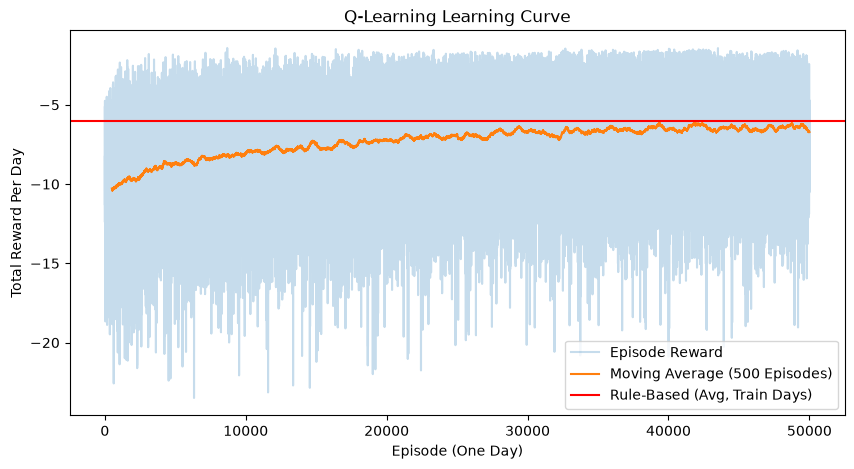

In [86]:
# Plotting baseline Q-Learning Learning Curve

rule_based_train_metrics, _ = evaluate(env, train_days, rule_based_policy)

plt.figure(figsize=(10,5))
plt.plot(episode_rewards, alpha=0.25, label='Episode Reward')
plt.plot(pd.Series(episode_rewards).rolling(500).mean(), label='Moving Average (500 Episodes)')
plt.axhline(rule_based_train_metrics['avg_daily_reward'], color='red', label='Rule-Based (Avg, Train Days)')
plt.xlabel('Episode (One Day)')
plt.ylabel('Total Reward Per Day')
plt.title('Q-Learning Learning Curve')
plt.legend()
plt.show()

### Controllers and Comparison (No Battery vs Rule-Based vs Q-Learning)

In [87]:
# Creating controllers

# Compiling no-policy, rule-based, Q-Learning (RL) controllers
controllers = {
    'No Battery': no_battery_policy,
    'Rule-Based': rule_based_policy,
    'Q-Learning': Q_policy
}

# Evaluating metrics for each controller
rows = []
test_daily_costs = {}
for period, days in [('Train (2006-2008)', train_days), ('Validation (2009)', val_days), ('Test (2010)', test_days)]:
    for name, policy in controllers.items():
        metrics, daily_costs = evaluate(env, days, policy)
        if name == 'No Battery':
            base_cost = metrics['avg_daily_cost_$']
        metrics['savings_$_per_day'] = base_cost - metrics['avg_daily_cost_$']
        metrics['savings_%'] = 100 * metrics['savings_$_per_day'] / base_cost
        rows.append({'period': period, 'controller': name, **metrics})
        if period == 'Test (2010)':
            test_daily_costs[name] = daily_costs

results = pd.DataFrame(rows).round(4)
display(results)

,period,controller,avg_daily_cost_$,avg_daily_reward,avg_daily_peak_grid_kWh,violations_per_day,savings_$_per_day,savings_%
0,Train (2006-2008),No Battery,6.6727,-6.6727,3.0420,0.0000,0.0000,0.0000
1,Train (2006-2008),Rule-Based,5.7953,-6.0256,3.2210,0.4607,0.8774,13.1493
2,Train (2006-2008),Q-Learning,6.1818,-6.1933,3.7101,0.0230,0.4909,7.3565
3,Validation (2009),No Battery,6.5111,-6.5111,2.7697,0.0000,0.0000,0.0000
4,Validation (2009),Rule-Based,5.5346,-5.7770,2.9075,0.4847,0.9765,14.9972
5,Validation (2009),Q-Learning,5.9661,-5.9772,3.5938,0.0223,0.5451,8.3715
6,Test (2010),No Battery,6.2716,-6.2716,2.5846,0.0000,0.0000,0.0000
7,Test (2010),Rule-Based,5.3690,-5.5967,2.9868,0.4554,0.9026,14.3924
8,Test (2010),Q-Learning,5.8022,-5.8102,3.5694,0.0159,0.4694,7.4842


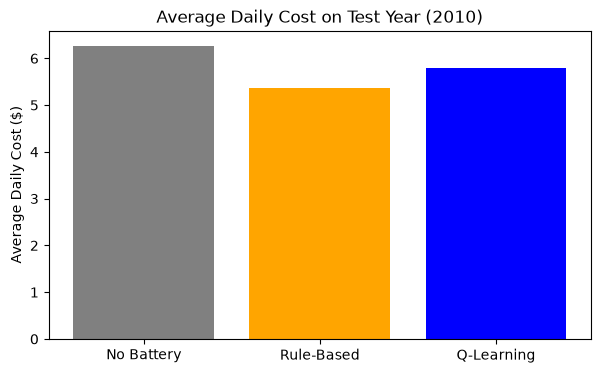

In [88]:
# Plotting metrics of each controller

test_results = results[results['period'] == 'Test (2010)']
plt.figure(figsize=(7,4))
plt.bar(test_results['controller'], test_results['avg_daily_cost_$'], color=['gray', 'orange', 'blue'])
plt.ylabel('Average Daily Cost ($)')
plt.title('Average Daily Cost on Test Year (2010)')
plt.show()

### Policy Analysis and Seasonal Generalization

Typical Winter Day:


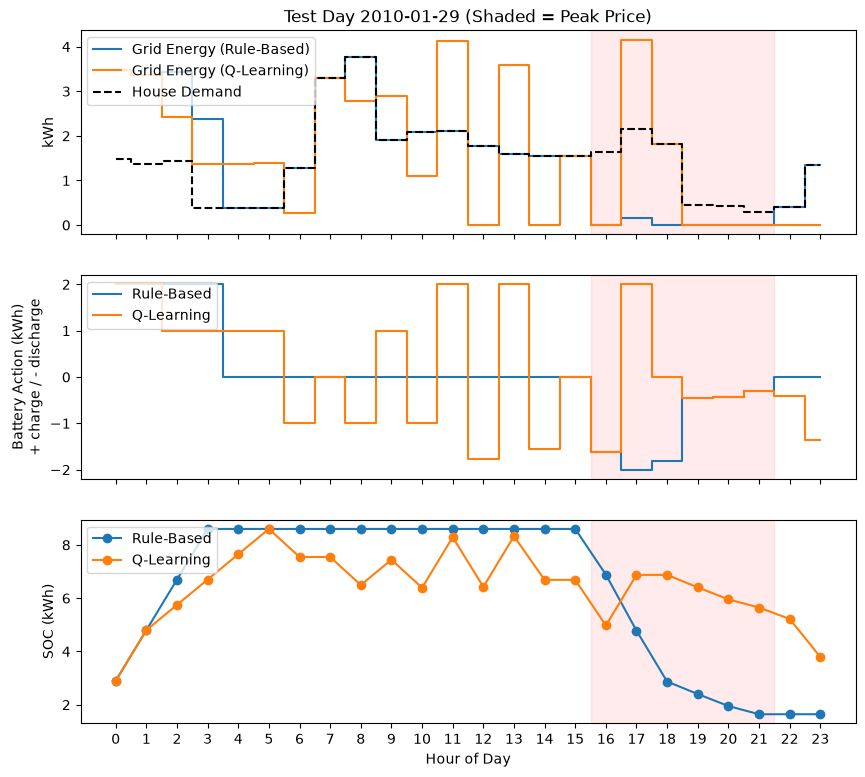

Typical Summer Day:


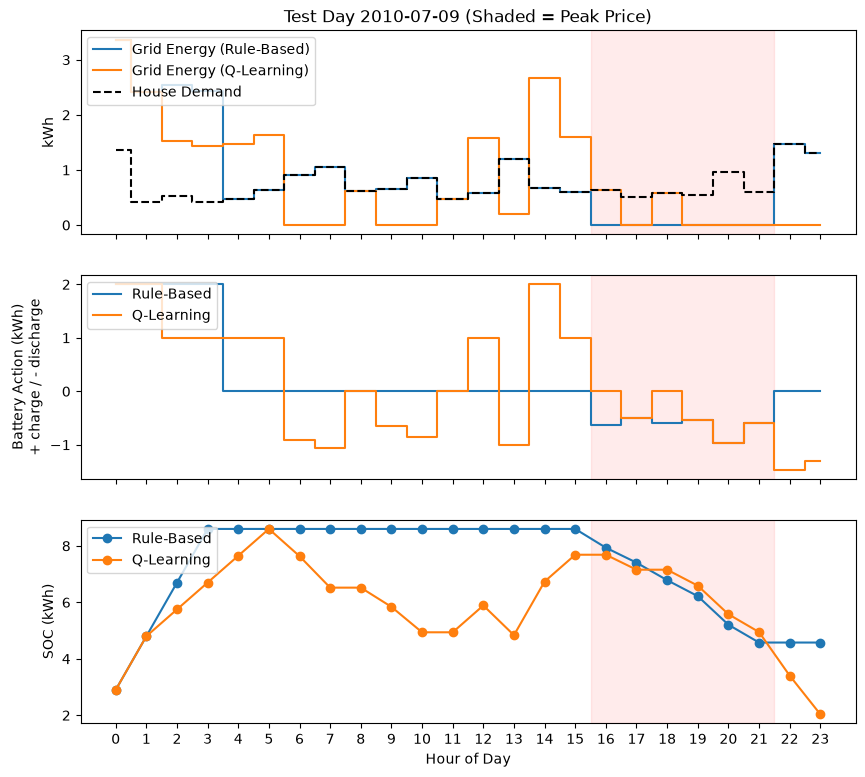

In [89]:
# Creating functions to simulate a typical day and plot it

# Function to pick a typical day --> the median total-demand day of a specified month
def typical_day(month):
    indexes = [i for i, date in enumerate(test_dates) if date.month == month]
    totals = test_days[indexes].sum(axis=1)
    return indexes[np.argsort(totals)[len(totals) // 2]]

# Function to create plots for simulated typical day
def plot_day(day_index):
    hours = np.arange(N_HOURS)
    fig, axes = plt.subplots(3, 1, figsize=(10,9), sharex=True)
    for name, policy in [('Rule-Based', rule_based_policy), ('Q-Learning', Q_policy)]:
        log = simulate_day(env, test_days[day_index], policy)
        axes[0].step(hours, log['grid'], where='mid', label=f'Grid Energy ({name})')
        axes[1].step(hours, log['action_kwh'], where='mid', label=name)
        axes[2].plot(hours, log['soc'], marker='o', label=name)
    axes[0].step(hours, test_days[day_index], where='mid', color='black', linestyle='--', label='House Demand')

    axes[0].set_ylabel('kWh')
    axes[1].set_ylabel('Battery Action (kWh)\n+ charge / - discharge')
    axes[2].set_ylabel('SOC (kWh)')
    axes[2].set_xlabel('Hour of Day')
    for ax in axes:
        ax.axvspan(15.5, 21.5, color='red', alpha=0.08)
        ax.legend(loc='upper left')
    axes[2].set_xticks(hours)
    axes[0].set_title(f'Test Day {test_dates[day_index]} (Shaded = Peak Price)')
    plt.show()

# Simulating and plotting typical winter day
print("Typical Winter Day:")
plot_day(typical_day(1)) # typical winter day

# Simulating and plotting typical summer day
print("Typical Summer Day:")
plot_day(typical_day(7)) # typical summer day

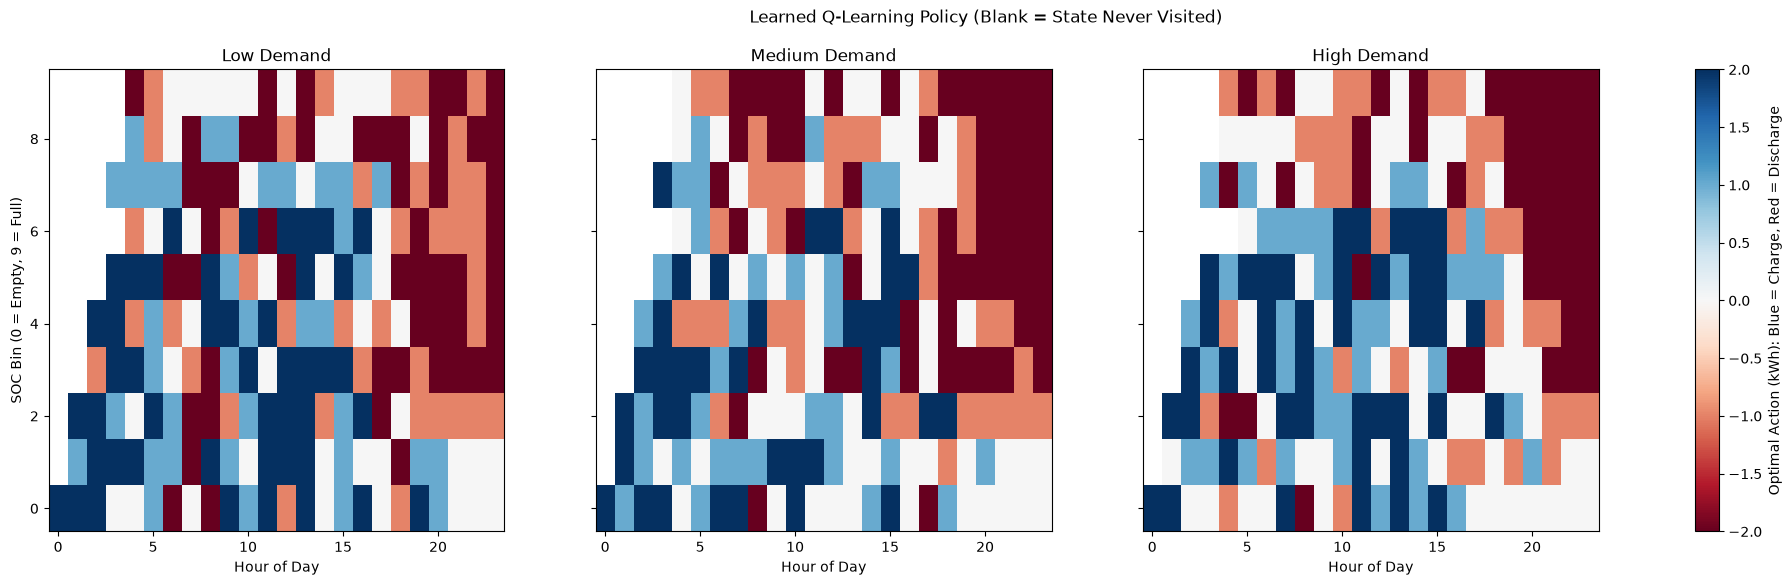

In [90]:
# Creating heatmap visualizations of Q-Learning Policy for low, medium, and high demands individually

optimal_action_kwh = np.array(ACTIONS, dtype=float)[np.argmax(Q, axis=3)]
optimal_action_kwh[~Q.any(axis=3)] = np.nan

fig, axes = plt.subplots(1, 3, figsize=(25,6), sharey=True)
for demand_bin, label in enumerate(['Low', 'Medium', 'High']):
    image = axes[demand_bin].imshow(optimal_action_kwh[:, :, demand_bin].T, origin='lower', aspect='auto',
        cmap='RdBu', vmin=-2, vmax=2)
    axes[demand_bin].set_title(f'{label} Demand')
    axes[demand_bin].set_xlabel('Hour of Day')
axes[0].set_ylabel('SOC Bin (0 = Empty, 9 = Full)')
fig.colorbar(image, ax=axes, label='Optimal Action (kWh): Blue = Charge, Red = Discharge')
fig.suptitle('Learned Q-Learning Policy (Blank = State Never Visited)')
plt.show()

In [91]:
# Average daily cost and savings of each policy by season (test year 2010 only; winter = Jan-Feb, no December data)

season_of_month = {1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring', 6: 'Summer',
                   7: 'Summer', 8: 'Summer', 9: 'Fall', 10: 'Fall', 11: 'Fall', 12: 'Winter'}
season_costs = pd.DataFrame(test_daily_costs)
season_costs['Season (2010)'] = [season_of_month[date.month] for date in test_dates]

# Average daily cost ($/day) of each policy per season
season_table = season_costs.groupby('Season (2010)').mean()
season_table = season_table.reindex(['Winter', 'Spring', 'Summer', 'Fall']) 

# Savings compared with no battery (%)
season_table['Rule-Based Savings (%)'] = 100 * (1 - season_table['Rule-Based'] / season_table['No Battery'])
season_table['Q-Learning Savings (%)'] = 100 * (1 - season_table['Q-Learning'] / season_table['No Battery'])

# Add units to the cost columns
season_table = season_table.rename(columns={
    'No Battery': 'No Battery Cost ($/day)',
    'Rule-Based': 'Rule-Based Cost ($/day)',
    'Q-Learning': 'Q-Learning Cost ($/day)',
})

display(season_table.round(4).reset_index().style.hide(axis='index').format(precision=4))

Season (2010),No Battery Cost ($/day),Rule-Based Cost ($/day),Q-Learning Cost ($/day),Rule-Based Savings (%),Q-Learning Savings (%)
Winter,8.4693,7.2475,7.7762,14.4263,8.1842
Spring,6.4008,5.3903,5.8820,15.7869,8.1059
Summer,4.3549,3.9438,4.2082,9.4386,3.3674
Fall,6.6392,5.5573,6.0384,16.2951,9.0487


In [92]:
# AI-Assisted

# Generalization Test: train Q-Learning on Summer days only, test on Winter days

train_months = np.array([date.month for date in train_dates])
test_months = np.array([date.month for date in test_dates])
summer_train_days = train_days[np.isin(train_months, [6, 7, 8])]
winter_test_days = test_days[np.isin(test_months, [1, 2, 12])]

Q_summer, _ = train_rl_model(env, summer_train_days)

rows = []
for name, policy in [('No Battery', no_battery_policy),
                     ('Rule-Based', rule_based_policy),
                     ('Q-Learning (Trained All Year)', Q_policy),
                     ('Q-Learning (Trained Summer Only)', make_Q_policy(Q_summer))]:
    metrics, _ = evaluate(env, winter_test_days, policy)
    rows.append({'Controller': name, **metrics})
print(f"Summer Training Days: {len(summer_train_days)}, Winter Test Days: {len(winter_test_days)}")
display(pd.DataFrame(rows).round(4))

Summer Training Days: 181, Winter Test Days: 56


,Controller,avg_daily_cost_$,avg_daily_reward,avg_daily_peak_grid_kWh,violations_per_day
0,No Battery,8.4693,-8.4693,3.3579,0.0000
1,Rule-Based,7.2475,-7.5690,3.3801,0.6429
2,Q-Learning (Trained All Year),7.7762,-7.7762,4.0188,0.0000
3,Q-Learning (Trained Summer Only),7.7706,-7.9224,4.0191,0.3036


### Parameter Study

In [93]:
# AI-Assisted

# Parameter study for various hyperparameters used in reinforcement learning model against Rule-Based policy

# Various hyperparameter definitions to be experimented with
# One hyperparameter changed at a time
# Range of options for each hyperparameter
# Each experiment: (parameter name, value, environment settings, training settings)
# Everything not listed stays at the baseline value
# Scored on the validation year (2009) so the test year (2010) stays unseen
experiments = (
    [('alpha', a, {}, {'alpha': a}) for a in [0.01, 0.1, 0.5]]
    + [('gamma', g, {}, {'gamma': g}) for g in [0.5, 0.9, 1.0]]
    + [('epsilon_decay', d, {}, {'eps_decay': d}) for d in [0.1, 0.4, 0.8]]
    + [('penalty', p, {'penalty': p}, {}) for p in [0.0, 0.5, 2.0]]
    + [('episodes', n, {}, {'n_episodes': n}) for n in [5500, 20000, 50000, 100000]]
)

# Evaluating metrics for each parameter study against Rule-Based policy
study_rows = []
study_curves = {}
for parameter, value, env_settings, train_settings in experiments:
    # Simulate battery --> Create a battery environment with this experiment's settings
    study_env = BatteryEnv(prices=PRICES, **env_settings)
    Q_run, rewards_run = train_rl_model(study_env, train_days, **train_settings)
    Q_metrics, _ = evaluate(study_env, val_days, make_Q_policy(Q_run))
    rule_based_metrics, _ = evaluate(study_env, val_days, rule_based_policy)
    study_rows.append({'parameter': parameter, 'value': value, 
                       'Q avg_daily_cost_$': Q_metrics['avg_daily_cost_$'],
                       'Q violations_per_day': Q_metrics['violations_per_day'],
                       'Q avg_daily_peak_grid_kWh': Q_metrics['avg_daily_peak_grid_kWh'],
                       'Rule-Based avg_daily_cost_$': rule_based_metrics['avg_daily_cost_$']})
    study_curves[(parameter, value)] = rewards_run
    print(f"Completed: {parameter} = {value}")

study = pd.DataFrame(study_rows).round(4)
display(study)

Completed: alpha = 0.01
Completed: alpha = 0.1
Completed: alpha = 0.5
Completed: gamma = 0.5
Completed: gamma = 0.9
Completed: gamma = 1.0
Completed: epsilon_decay = 0.1
Completed: epsilon_decay = 0.4
Completed: epsilon_decay = 0.8
Completed: penalty = 0.0
Completed: penalty = 0.5
Completed: penalty = 2.0
Completed: episodes = 5500
Completed: episodes = 20000
Completed: episodes = 50000
Completed: episodes = 100000


,parameter,value,Q avg_daily_cost_$,Q violations_per_day,Q avg_daily_peak_grid_kWh,Rule-Based avg_daily_cost_$
0,alpha,0.01,6.1472,0.5822,3.8582,5.5346
1,alpha,0.10,5.9661,0.0223,3.5938,5.5346
2,alpha,0.50,6.3311,0.3593,3.6268,5.5346
3,gamma,0.50,6.5111,0.0000,2.7697,5.5346
4,gamma,0.90,6.1976,0.2173,3.2776,5.5346
5,gamma,1.00,5.9661,0.0223,3.5938,5.5346
6,epsilon_decay,0.10,5.8865,0.1170,3.4777,5.5346
7,epsilon_decay,0.40,5.9618,0.0251,3.6875,5.5346
8,epsilon_decay,0.80,5.9661,0.0223,3.5938,5.5346
9,penalty,0.00,5.8316,3.2591,3.6069,5.5346


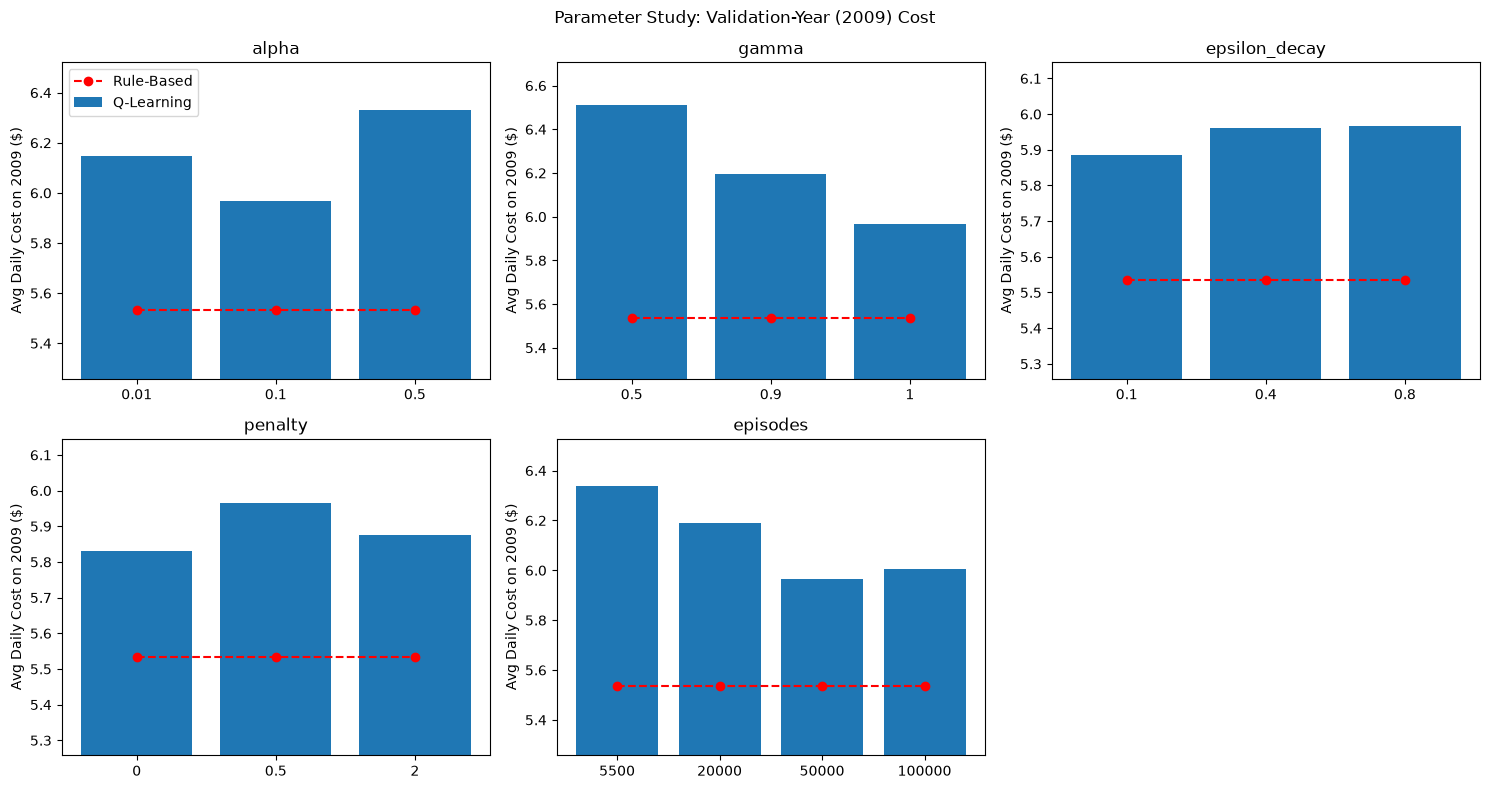

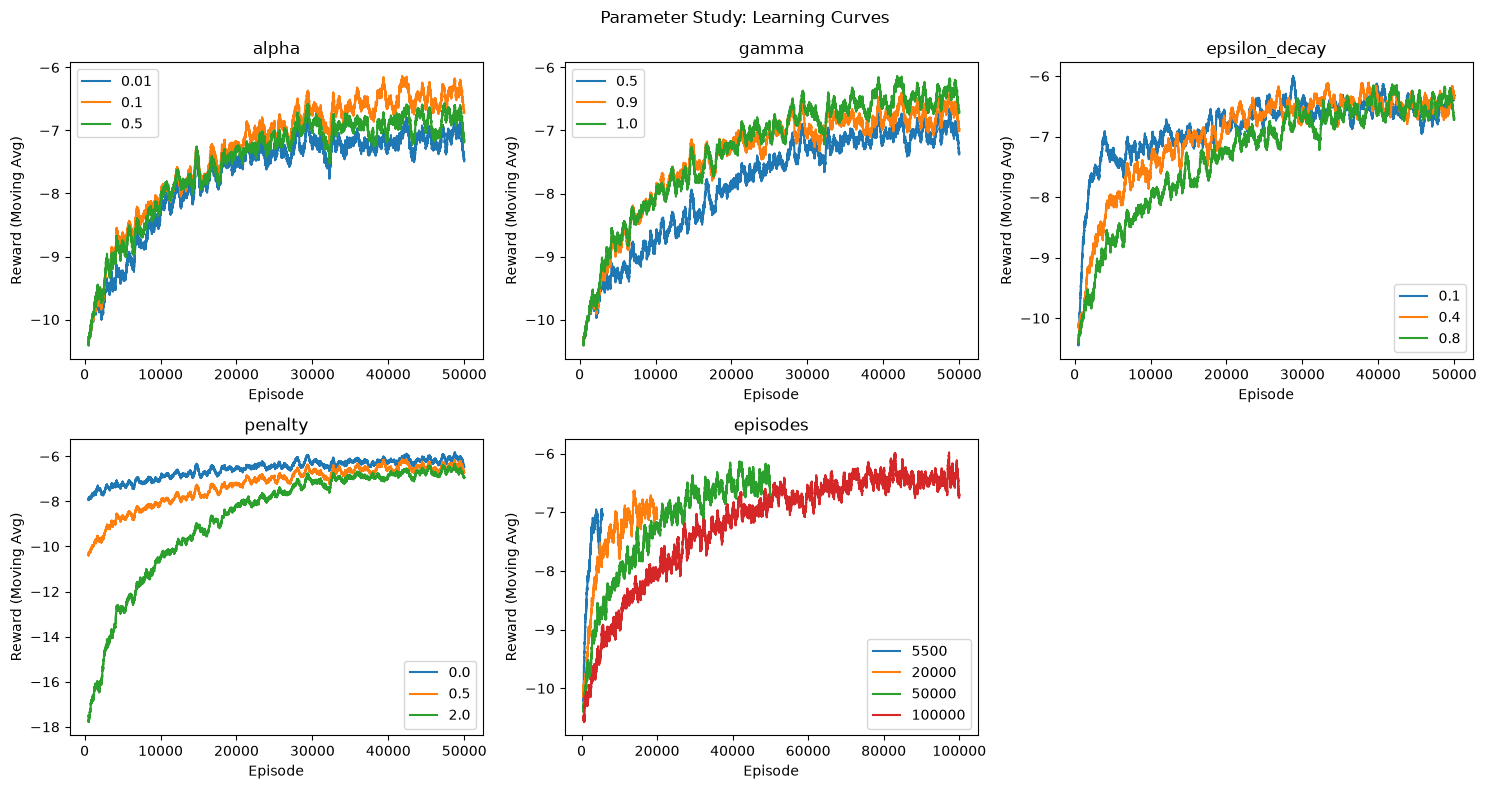

In [94]:
# Plotting results/metrics from the parameter study

parameters = study['parameter'].unique()

# Plot bar graphs of each grouped hyperparameter for comparison/evaluation
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, parameter in zip(axes.flat, parameters):
    part = study[study['parameter'] == parameter]
    labels = [f'{value:g}' for value in part['value']] # e.g., 5500 instead of 5500.0
    ax.bar(labels, part['Q avg_daily_cost_$'], label='Q-Learning')
    ax.plot(labels, part['Rule-Based avg_daily_cost_$'], 'r--o', label='Rule-Based')
    costs = pd.concat([part['Q avg_daily_cost_$'], part['Rule-Based avg_daily_cost_$']])
    ax.set_ylim(costs.min() * 0.95, costs.max() * 1.03)
    ax.set_title(parameter)
    ax.set_ylabel('Avg Daily Cost on 2009 ($)')
axes[0, 0].legend()
axes.flat[-1].axis('off') # 5 parameters, 6 panels: hide the unused one
fig.suptitle('Parameter Study: Validation-Year (2009) Cost')
plt.tight_layout()
plt.show()

# Plot learning curves of rolling means of each parameter study
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, parameter in zip(axes.flat, parameters):
    for (name, value), rewards_run in study_curves.items():
        if name == parameter:
            ax.plot(pd.Series(rewards_run).rolling(500).mean(), label=str(value))
    ax.set_title(parameter)
    ax.set_xlabel('Episode')
    ax.set_ylabel('Reward (Moving Avg)')
    ax.legend()
axes.flat[-1].axis('off') # 5 parameters, 6 panels: hide the unused one
fig.suptitle('Parameter Study: Learning Curves')
plt.tight_layout()
plt.show()